[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/user/repo/blob/main/notebook.ipynb)

# Lecture 13
# Uncertainty partitioning for CMIP6 global mean temperature
- F : forced response of each model   (4th-order polynomial fit)
- I : internal variability            (variance of residual = data - F)
- M : model uncertainty               (variance across models of F)
- S : scenario uncertainty            (variance across scenario means of F)

In [5]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
 
scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

## 1. Read data: one file per scenario, rows = years, columns = models

In [15]:
data = {}
for s in scenarios:
    df = pd.read_csv(f"data/cmip6_{s}.csv", index_col="year")
    # anomaly relative to 1995-2014
    df = df - df.loc[1995:2014].mean()          
    data[s] = df
models = data["ssp585"].columns
years = data["ssp585"].index.values



##  2. Forced response F: 4th-order polynomial fit for each model/scenario

- Standardize time (predictors)
- create predictors: x, x2, x3, x4
- conducting fit to get the fitted trend

### 2.1 For one scneario, one model  - review trend and residual 

In [23]:
# rescaled time for a stable fit
x = (years - years.mean()) / years.std()
# columns: 1, x, x², x³, x⁴
X = np.column_stack([x**k for k in range(4 + 1)])   # columns: 1, x, x², x³, x⁴
X[0,:]


array([ 1.        , -1.72054204,  2.9602649 , -5.0932602 ,  8.76316828])

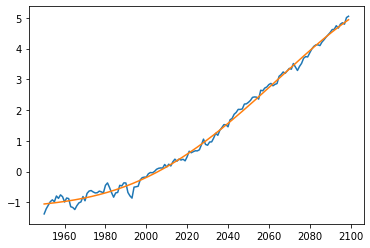

In [24]:
# get global mean T from a single model under rssp585 and apply OLS fit
Data1 = data["ssp585"]['cmip6_M01']
res = sm.OLS(Data1.values, X).fit()
Data1_fit  = res.fittedvalues
plt.plot(years, Data1)
plt.plot(years, Data1_fit)

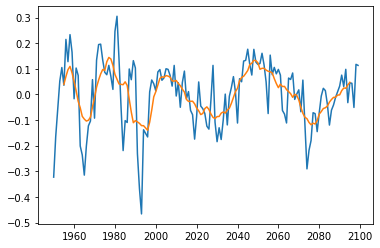

In [25]:
# get residual and apply 10-yr running mean (using panda array functino)
resid = (data[s]['cmip6_M01'] - Data1_fit).rolling(10, center=True).mean()
plt.plot(years,data[s]['cmip6_M01'] - Data1_fit)
plt.plot(years,resid)

### 2.2 For multiple models and multiple scenarios (F, I, M, S)

In [27]:
F = {}
for s in scenarios:
    F[s] = pd.DataFrame(index=years, columns=models, dtype=float)
    for m in models:
        res = sm.OLS(data[s][m].values, X).fit()
        F[s][m] = res.fittedvalues
    ### all forced responses is reletive to 1995 to 2014 mean (optiona)
    F[s] = F[s] - F[s].loc[1995:2014].mean()

Text(0.5, 1.0, 'ssp585')

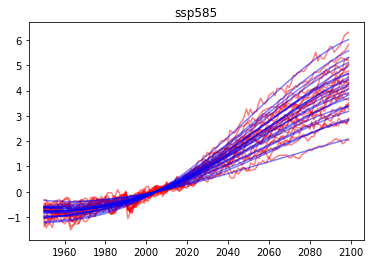

In [28]:
### chcekc results using the last ssp in the scnearios
plt.plot(years,data[s],'r',alpha=0.5);
plt.plot(years,F[s],'b',alpha=0.5);
plt.title(s)


### 3. Internal variability I
 one number per model and scenario, then average all of them

In [29]:
I_values = []
for s in scenarios:
    resid = (data[s] - F[s]).rolling(10, center=True).mean()
    I_values.extend(resid.var(axis=0))          # variance over time, per model
I = np.mean(I_values)                           # single number (K^2), constant in time
print(I)

0.004278981510283922


### 4. Model uncertainty M: variance across models of F (SSP5-8.5), each year

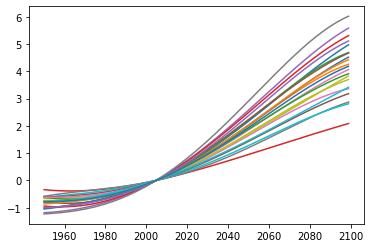

In [30]:
plt.plot(F["ssp585"]);

In [32]:
M = F["ssp585"].var(axis=1, ddof=0) # population; CMIP6 is an ensmelbe of possibility not a random sample of all possible models.
print(M)

1950    0.046185
1951    0.045126
1952    0.044151
1953    0.043247
1954    0.042402
          ...   
2095    0.882516
2096    0.893945
2097    0.904888
2098    0.915324
2099    0.925235
Length: 150, dtype: float64


###  5. Scenario uncertainty S: variance across the multimodel mean of each scenario

1950    0.001009
1951    0.000661
1952    0.000430
1953    0.000291
1954    0.000225
          ...   
2095    1.583481
2096    1.623719
2097    1.663384
2098    1.702380
2099    1.740607
Length: 150, dtype: float64


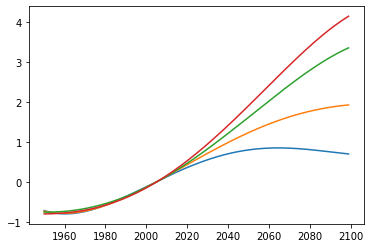

In [37]:
scen_means = pd.DataFrame({s: F[s].mean(axis=1) for s in scenarios})
S = scen_means.var(axis=1, ddof=0)
plt.plot(scen_means);
print(S)

### 6. Fractions of total variance T = I + M + S

In [44]:

T = I + M + S
frac = pd.DataFrame({"Internal": I / T, "Model": M / T, "Scenario": S / T}) * 100

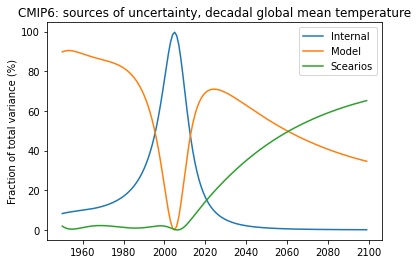

In [47]:

plt.plot(years,frac['Internal'],label = 'Internal')
plt.plot(years,frac['Model'],label = "Model")
plt.plot(years,frac['Scenario'],label = "Scearios")
plt.title("CMIP6: sources of uncertainty, decadal global mean temperature")
plt.legend()
plt.ylabel("Fraction of total variance (%)")
plt.xlim()
plt.savefig('CMIP6.png',dpi = 200)

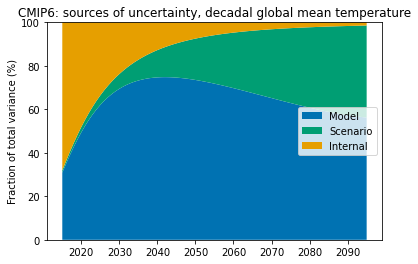

In [14]:
 
# simple plot of the fractions, 2015-2095
f = frac.loc[2015:2095]
plt.stackplot(f.index, f["Model"], f["Scenario"], f["Internal"],
              labels=["Model", "Scenario", "Internal"],
              colors=["#0072B2", "#009E73", "#E69F00"])
plt.ylim(0, 100)
plt.ylabel("Fraction of total variance (%)")
plt.title("CMIP6: sources of uncertainty, decadal global mean temperature")
plt.legend(loc="center right")
plt.savefig("cmip6_fractions.png", dpi=150)
plt.show()

In [51]:
print(f"Internal fraction 2050 (%): {frac.loc[2050, 'Internal']:.3f}")
print(f"Model fraction 2050 (%): {frac.loc[2050, 'Model']:.3f}")

Internal fraction 2050 (%): 1.074
Model fraction 2050 (%): 56.051


## Signal-to-noise ratio
- Signal G(t) = multimodel, multi-scenario mean change (mean of scen_means)
- Noise       = 90% half-width of the uncertainty, 1.645 * sqrt(variance)
- S/N > 1     : expected change exceeds the 90% uncertainty range

In [55]:
    
G = scen_means.mean(axis=1)
 
SN_total = G / (1.645 * np.sqrt(I + M + S))     # all three sources
SN_noModel = G / (1.645 * np.sqrt(I + S))       # if model uncertainty were removed
SN_internal = G / (1.645 * np.sqrt(I))          # vs. internal variability only

(2015.0, 2100.0)

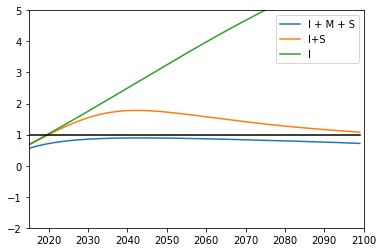

In [59]:
plt.plot(years,SN_total,label='I + M + S')
plt.plot(years,SN_noModel,label ='I+S')
plt.plot(years,SN_internal,label = 'I')
plt.plot(years,years*0+1,'k')
plt.legend()
plt.ylim([-2,5])
plt.xlim([2015,2100])

# Hands-on

In [52]:

scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]
 
# 1. Read data (rows = years, columns = models) and make anomalies
data = {}
for s in scenarios:
    df = pd.read_csv(f"data/cmip6_britishisles_tas_{s}.csv", index_col="year")
    data[s] = df - df.loc[1995:2014].mean()      # anomaly relative to 1995-2014
 
